# 10 · Final analysis — every table and figure for the report / PPT


**Owner:** anyone · **GPU:** none needed (CPU runtime is fine; the qualitative cells read images from the packs).
Collects every experiment record, re-creates all tables/figures from them, and writes `Final_Project_Results/report/summary.md`.
Re-run any time; it only reads results. Figures are saved at 200 dpi in `figures/`, tables as CSV + Markdown in `tables/`.

In [1]:
# ===== 0. Setup — identical in every notebook. Runtime > Change runtime type > T4 GPU =====
SMOKE_TEST = False   # True: 16 train / 8 val images, 1 epoch — checks the whole pipeline in minutes
DRIVE_ROOT = "/content/drive/MyDrive/MAVREC"   # shared team folder (each member: "Add shortcut to Drive")

import os, sys, subprocess, importlib
try:
    from google.colab import drive
    try:
        os.listdir("/content/drive/MyDrive")   # raises if the Drive FUSE mount went stale
        drive.mount("/content/drive")
    except OSError:  # "Transport endpoint is not connected" after a Drive hiccup: remount
        drive.mount("/content/drive", force_remount=True)
except ImportError:
    print("Not in Colab — make sure DRIVE_ROOT exists locally.")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.173", "transformers==5.18.0", "pycocotools>=2.0.8", "timm>=1.0.15", "tabulate", "tensorboard", "seaborn"], check=True)

CODE_DIR = os.path.join(DRIVE_ROOT, "Final_Project_Code")
assert os.path.exists(os.path.join(CODE_DIR, "mavrec_lib.py")), "Run 00_Setup_and_Data_Preparation first (it installs mavrec_lib.py)."
sys.path.insert(0, CODE_DIR)
import mavrec_lib as ml; importlib.reload(ml)
CFG = ml.setup(DRIVE_ROOT, smoke=SMOKE_TEST or None, require_gpu=False)
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
N_SMALL, N_SCREEN, N_LARGE = ml.TRAIN_SIZES      # 500, 1000, 2000

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Environment:
  python       : 3.13.15
  torch        : 2.11.0+cu130
  cuda         : True
  torchvision  : 0.26.0+cu130
  ultralytics  : 8.4.173
  transformers : 5.18.0
  pycocotools  : 2.0.11
  numpy        : 2.1.3
  lib          : 1.0.0
  gpu          : Tesla T4
  gpu_mem_gb   : 14.6


## 1 · Master results + status

In [2]:
ALL = ml.export_master_csv()
display(ml.status_board())
display(ml.show_decisions())
V = ALL[(ALL.eval_split == "val") & (ALL.comparable == True)]
REF = ALL[ALL.comparable == False]
print(len(ALL), "evaluation rows;", ALL.experiment_id.nunique(), "experiments")

Saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/master_results.csv (36, 42)


,experiment_id,status,evals,train_time_h,updated
0,PAPER_ddetr_coco_aerial_test,reference,1,NaN,2026-10-06 14:30:43
1,PAPER_ddetr_ground_aerial_test,reference,1,NaN,2026-10-06 14:30:43
2,PAPER_yolov7_aerial_full,reference,1,NaN,2026-10-06 14:30:43
3,R2_yolov7_n500_r640_review2,reference,1,NaN,2026-10-06 14:30:43
4,R2_yolov7_n500_r960_review2,reference,1,NaN,2026-10-06 14:30:43
5,S0_yolov7_n500_r640_full_COCO_s42,done,2,0.775,2026-10-13 06:54:34
6,S0_yolov7_n500_r960_full_COCO_s42,done,1,0.407,2026-10-08 06:17:29
7,S1_deformable_detr_n1000_r960_full_COCO_s42,done,1,3.840,2026-10-06 23:11:05
8,S1_frcnn_r50_v1_n1000_r960_full_COCO_s42,done,1,0.643,2026-10-08 07:24:28
9,S1_frcnn_r50_v2_n1000_r960_full_COCO_s42,done,1,0.775,2026-10-08 06:43:19


,key,value,reason,set
0,S1_best_model,yolov8m,7 candidates: S1_deformable_detr_n1000_r960_fu...,2026-10-09 13:58:08
1,finalists,"[yolov8m, frcnn_r50_v2]",4 candidates: S1_deformable_detr_n1000_r960_fu...,2026-10-09 13:58:08
2,best_model,yolov8m,6 candidates: S2_frcnn_r50_v2_n1000_r640_full_...,2026-10-09 15:46:53
3,best_res,1280,lowest resolution within 1 AP (mAP & APS) of t...,2026-10-09 15:46:53
4,use_tiling,False,"tile-trained, sliced vs full-frame 1280: {'del...",2026-10-10 15:29:04
5,tiling_mode,sliced,best tile-trained inference mode on val (APS),2026-10-10 15:29:04
6,scaling_gain_per_doubling,3.86,log-linear fit over 500/1000/2000,2026-10-10 17:16:56
7,use_ground,False,COCO->ground->aerial vs COCO->aerial at 1000 f...,2026-10-13 05:56:54
8,ground_exp,S5_yolov8m_g2000_r1280_full_COCO_s42_groundonly,ground-pretrained checkpoint used as init in n...,2026-10-13 05:56:54
9,final_model,S3_yolov8m_n2000_r1280_full_COCO_s42,last cumulative ablation row,2026-10-13 10:48:56


36 evaluation rows; 29 experiments


## 2 · Stage 1 model comparison + multi-metric selection table

,experiment_id,model_family,model_version,resolution,dataset_size,mAP50_95,APS,mAP50,recall,precision,F1,FPS,GPU_memory_infer_GB,parameters_M,rank_mAP50_95,rank_APS,rank_mAP50,rank_recall,rank_precision,rank_F1,rank_FPS,rank_GPU_memory_infer_GB,rank_parameters_M
0,S1_yolov8m_n1000_r960_full_COCO_s42,YOLO,yolov8m,960.0,1000,61.181,29.502,87.426,83.626,91.616,87.439,38.89,0.12,25.86,1.0,5.0,1.0,4.0,3.0,4.0,2.0,1.0,2.0
1,S1_yolo11m_n1000_r960_full_COCO_s42,YOLO,yolo11m,960.0,1000,59.174,31.211,86.258,84.234,92.043,87.965,38.00,0.15,20.06,2.0,3.0,2.0,3.0,2.0,3.0,3.0,2.0,1.0
2,S1_frcnn_r50_v2_n1000_r960_full_COCO_s42,Two-stage,frcnn_r50_v2,960.0,1000,55.522,36.051,78.872,84.301,92.671,88.288,16.94,0.43,43.30,3.0,1.0,4.0,2.0,1.0,2.0,5.0,5.0,7.0
3,S1_rtdetr-l_n1000_r960_full_COCO_s42,Transformer,rtdetr-l,960.0,1000,52.887,34.665,82.186,86.293,90.803,88.490,13.51,0.25,32.83,4.0,2.0,3.0,1.0,4.0,1.0,6.0,4.0,3.0
4,S1_frcnn_r50_v1_n1000_r960_full_COCO_s42,Two-stage,frcnn_r50_v1,960.0,1000,46.752,25.735,73.512,73.269,86.234,79.224,19.09,0.45,41.35,5.0,6.0,5.0,6.0,6.0,6.0,4.0,6.0,6.0
5,S1_yolov7_n1000_r960_full_COCO_s42,YOLO,yolov7,960.0,1000,45.833,30.769,73.046,83.148,90.223,86.541,39.47,0.19,36.53,6.0,4.0,6.0,5.0,5.0,5.0,1.0,3.0,4.0
6,S1_deformable_detr_n1000_r960_full_COCO_s42,Transformer,deformable_detr,960.0,1000,19.566,7.411,38.905,53.982,67.106,59.833,7.01,0.87,40.05,7.0,7.0,7.0,7.0,7.0,7.0,7.0,7.0,5.0


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/R_model_comparison_S1.csv
7 candidates: S1_deformable_detr_n1000_r960_full_COCO_s42, S1_frcnn_r50_v1_n1000_r960_full_COCO_s42, S1_frcnn_r50_v2_n1000_r960_full_COCO_s42, S1_rtdetr-l_n1000_r960_full_COCO_s42, S1_yolo11m_n1000_r960_full_COCO_s42, S1_yolov7_n1000_r960_full_COCO_s42, S1_yolov8m_n1000_r960_full_COCO_s42
mAP50_95: best 61.18; within 1.0 -> ['S1_yolov8m_n1000_r960_full_COCO_s42']
SELECTED: S1_yolov8m_n1000_r960_full_COCO_s42
saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/R_model_comparison.png


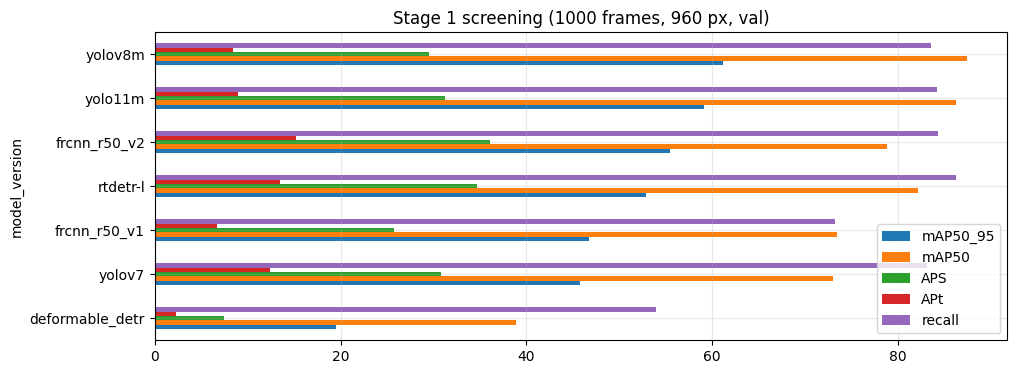

In [3]:
S1 = V[V.stage == "S1"]
if len(S1):
    T1 = ml.selection_table(S1); display(T1); ml.save_table(T1, "R_model_comparison_S1")
    best, why = ml.select_best(S1, verbose=False); print(why)
    fig, ax = plt.subplots(figsize=(11, 4))
    S1.set_index("model_version")[["mAP50_95", "mAP50", "APS", "APt", "recall"]].sort_values("mAP50_95").plot.barh(ax=ax)
    ax.set_title("Stage 1 screening (1000 frames, 960 px, val)"); ax.grid(alpha=.3); ml.savefig("R_model_comparison.png"); plt.show()

## 3 · Accuracy vs speed / size

saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/R_accuracy_vs_fps_and_size.png


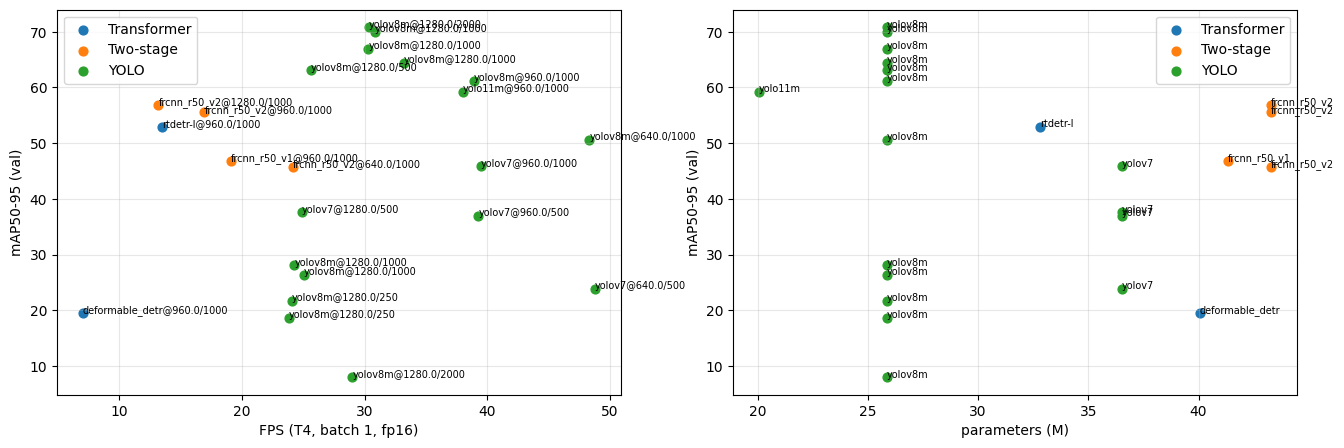

In [4]:
P = V[V.inference_mode == "full"].dropna(subset=["FPS"])
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for fam, g in P.groupby("model_family"):
    ax[0].scatter(g.FPS, g.mAP50_95, label=fam, s=40); ax[1].scatter(g.parameters_M, g.mAP50_95, label=fam, s=40)
    for r in g.itertuples():
        ax[0].annotate(f"{r.model_version}@{r.resolution}/{r.dataset_size}", (r.FPS, r.mAP50_95), fontsize=7)
        ax[1].annotate(r.model_version, (r.parameters_M, r.mAP50_95), fontsize=7)
ax[0].set_xlabel("FPS (T4, batch 1, fp16)"); ax[1].set_xlabel("parameters (M)")
for a in ax: a.set_ylabel("mAP50-95 (val)"); a.legend(); a.grid(alpha=.3)
ml.savefig("R_accuracy_vs_fps_and_size.png"); plt.show()

## 4 · Resolution, data scaling, tiling, ground pretraining (re-drawn from records)

saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/R_resolution_and_scaling.png


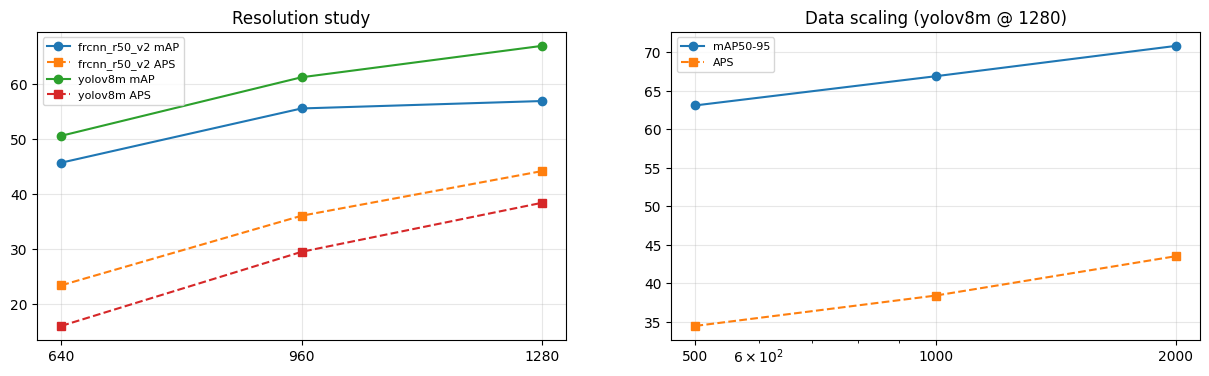

saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/R_resolution.csv
saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/R_data_scaling.csv


In [5]:
D = ml.show_decisions().set_index("key")["value"].to_dict() if len(ml.show_decisions()) else {}
BM, BR = D.get("best_model"), D.get("best_res")
if BM:
    fin = D.get("finalists", [BM])
    R = V[V.model_version.isin(fin) & (V.dataset_size == N_SCREEN) & (V.tiling == "none") & (V.pretraining == "COCO") & V.stage.isin(["S1", "S2"]) & (V.inference_mode == "full")]
    S = V[(V.model_version == BM) & (V.resolution == BR) & (V.tiling == "none") & (V.pretraining == "COCO") & V.stage.isin(["S1", "S2", "S3"]) & (V.inference_mode == "full")]
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    for m, g in R.sort_values("resolution").groupby("model_version"):
        ax[0].plot(g.resolution, g.mAP50_95, "o-", label=f"{m} mAP"); ax[0].plot(g.resolution, g.APS, "s--", label=f"{m} APS")
    ax[0].set_title("Resolution study"); ax[0].set_xticks([640, 960, 1280])
    g = S.sort_values("dataset_size")
    ax[1].plot(g.dataset_size, g.mAP50_95, "o-", label="mAP50-95"); ax[1].plot(g.dataset_size, g.APS, "s--", label="APS")
    ax[1].set_xscale("log"); ax[1].set_xticks(list(ml.TRAIN_SIZES)); ax[1].set_xticklabels(ml.TRAIN_SIZES); ax[1].set_title(f"Data scaling ({BM} @ {BR})")
    for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
    ml.savefig("R_resolution_and_scaling.png"); plt.show()
    ml.save_table(R, "R_resolution"); ml.save_table(S, "R_data_scaling")

saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/R_APS_comparison.png


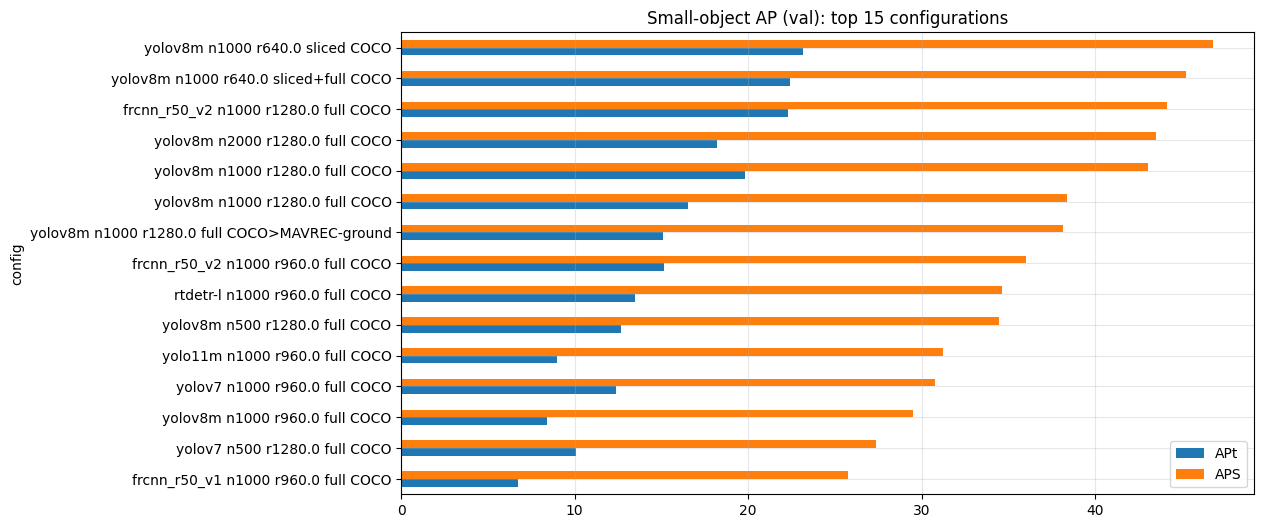

,experiment_id,stage,model_version,dataset_size,resolution,tiling,inference_mode,pretraining,mAP50_95,mAP50,APS,APt,APM,recall,F1,FPS,GPU_memory_infer_GB,parameters_M,train_time_h
25,S4_yolov8m_n1000_r640_tile_COCO_s42,S4,yolov8m,1000,640.0,tile_train,sliced,COCO,57.912,90.819,46.818,23.167,55.193,92.545,92.936,2.96,0.32,25.86,0.949
26,S4_yolov8m_n1000_r640_tile_COCO_s42,S4,yolov8m,1000,640.0,tile_train,sliced+full,COCO,56.249,90.612,45.264,22.423,54.967,90.423,91.125,2.45,0.32,25.86,0.949


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/R_tiling.csv


,experiment_id,stage,model_version,dataset_size,resolution,tiling,inference_mode,pretraining,mAP50_95,mAP50,APS,APt,APM,recall,F1,FPS,GPU_memory_infer_GB,parameters_M,train_time_h
27,S5_yolov8m_g2000_r1280_full_COCO_s42_groundonly,S5,yolov8m,2000,1280.0,none,full,COCO,7.992,12.943,0.362,0.002,3.160,14.949,18.481,29.01,0.15,25.86,0.225
28,S5_yolov8m_n1000_r1280_full_COCO2MAVRECground_s42,S5,yolov8m,1000,1280.0,none,full,COCO>MAVREC-ground,64.443,90.922,38.156,15.109,62.972,88.604,90.828,33.18,0.15,25.86,0.774
29,S5_yolov8m_n1000_r1280_full_COCO_s42_longer,S5,yolov8m,1000,1280.0,none,full,COCO,69.958,92.807,43.032,19.848,71.237,90.864,92.804,30.84,0.15,25.86,1.760


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/R_ground_pretraining.csv


In [6]:
APS_CMP = V[V.stage.isin(["S0", "S1", "S2", "S3", "S4", "S5", "S6"])].copy()
APS_CMP["config"] = APS_CMP.model_version + " n" + APS_CMP.dataset_size.astype(str) + " r" + APS_CMP.resolution.astype(str) + " " + APS_CMP.inference_mode + " " + APS_CMP.pretraining
top = APS_CMP.sort_values("APS", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(11, 6)); top.set_index("config")[["APt", "APS"]].iloc[::-1].plot.barh(ax=ax)
ax.set_title("Small-object AP (val): top 15 configurations"); ax.grid(alpha=.3); ml.savefig("R_APS_comparison.png"); plt.show()
for nm, st in [("tiling", "S4"), ("ground_pretraining", "S5")]:
    t = V[V.stage == st]
    if len(t):
        display(t[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"]]); ml.save_table(t[["experiment_id","stage","model_version","dataset_size","resolution","tiling","inference_mode","pretraining","mAP50_95","mAP50","APS","APt","APM","recall","F1","FPS","GPU_memory_infer_GB","parameters_M","train_time_h"]], f"R_{nm}")

## 5 · Final ablation (test set) + references

In [7]:
for split in ("val", "test"):
    p = os.path.join(CFG["tables_dir"], f"S6_ablation_{split}.csv")
    if os.path.exists(p):
        print(split.upper()); display(pd.read_csv(p))
print("Reference numbers (different protocols — not directly comparable):")
display(REF[["experiment_id", "eval_split", "mAP50_95", "mAP50", "APS", "APM", "recall", "notes"]])

VAL


,row,split,experiment_id,mAP50_95,mAP50,APS,APt,APM,recall,F1,FPS,latency_ms,parameters_M,train_time_h,Δ mAP vs prev,Δ APS vs prev
0,"A YOLOv7 · 500 · 640 (Review 2 setting, re-run)",val,S0_yolov7_n500_r640_full_COCO_s42,23.853,44.305,7.298,2.188,26.958,60.055,67.160,48.77,20.51,36.53,0.775,NaN,NaN
1,B + resolution 1280,val,S6_yolov7_n500_r1280_full_COCO_s42,37.572,65.914,27.346,10.073,42.796,82.789,85.702,24.90,40.15,36.53,0.543,13.72,20.05
2,C + architecture (yolov8m),val,S3_yolov8m_n500_r1280_full_COCO_s42,63.086,89.694,34.456,12.670,61.416,86.097,89.261,25.63,39.01,25.86,0.716,25.51,7.11
3,D + data (2000 frames),val,S3_yolov8m_n2000_r1280_full_COCO_s42,70.811,92.674,43.506,18.202,72.938,91.187,92.699,30.34,32.96,25.86,0.739,7.73,9.05


TEST


,row,split,experiment_id,mAP50_95,mAP50,APS,APt,APM,recall,F1,FPS,latency_ms,parameters_M,train_time_h,Δ mAP vs prev,Δ APS vs prev
0,"A YOLOv7 · 500 · 640 (Review 2 setting, re-run)",test,S0_yolov7_n500_r640_full_COCO_s42,21.870,41.381,6.801,2.732,22.700,56.132,64.018,46.40,21.55,36.53,0.775,NaN,NaN
1,B + resolution 1280,test,S6_yolov7_n500_r1280_full_COCO_s42,35.473,63.145,25.706,12.793,37.061,80.601,83.070,24.34,41.09,36.53,0.543,13.60,18.90
2,C + architecture (yolov8m),test,S3_yolov8m_n500_r1280_full_COCO_s42,59.246,87.717,34.405,16.227,59.413,84.536,86.929,30.05,33.28,25.86,0.716,23.77,8.70
3,D + data (2000 frames),test,S3_yolov8m_n2000_r1280_full_COCO_s42,68.554,91.165,43.848,22.276,69.133,88.646,90.315,30.02,33.32,25.86,0.739,9.31,9.44


Reference numbers (different protocols — not directly comparable):


,experiment_id,eval_split,mAP50_95,mAP50,APS,APM,recall,notes
0,PAPER_ddetr_coco_aerial_test,test,33.2,61.9,31.5,51.0,NaN,MAVREC paper Table 3: MS-COCO pretrained D-DET...
1,PAPER_ddetr_ground_aerial_test,test,44.8,71.5,42.9,72.4,NaN,MAVREC paper Table 3: MAVREC-ground pretrained...
2,PAPER_yolov7_aerial_full,val,31.3,57.7,34.2,61.2,NaN,"MAVREC paper Table 2, aerial val, 8,605 train ..."
3,R2_yolov7_n500_r640_review2,val,5.7,15.7,NaN,NaN,25.6,"Review 2: 500 train (zip order) / 100 val, 10 ..."
4,R2_yolov7_n500_r960_review2,val,15.4,35.7,NaN,NaN,36.6,"Review 2: 500/100, 10 epochs, batch 2, YOLOv7 ..."


## 6 · Final model: class-wise AP, size-bucket recall, confusion matrix

saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/R_classwise_AP.png


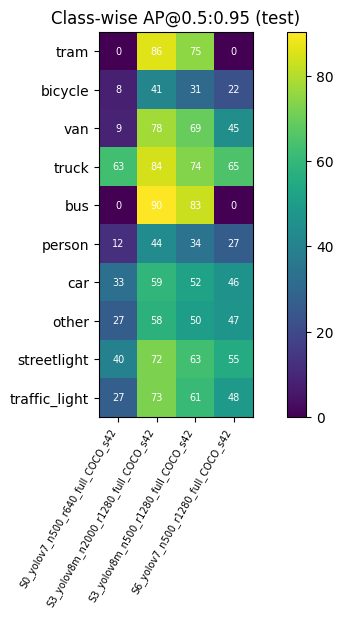

,n,recall
tiny,14826.0,70.28
small,41247.0,84.96
medium,53638.0,94.78
large,10806.0,97.71


saved /content/drive/MyDrive/MAVREC/Final_Project_Results/tables/R_final_size_bucket_recall.csv
saved /content/drive/MyDrive/MAVREC/Final_Project_Results/figures/R_final_confusion.png


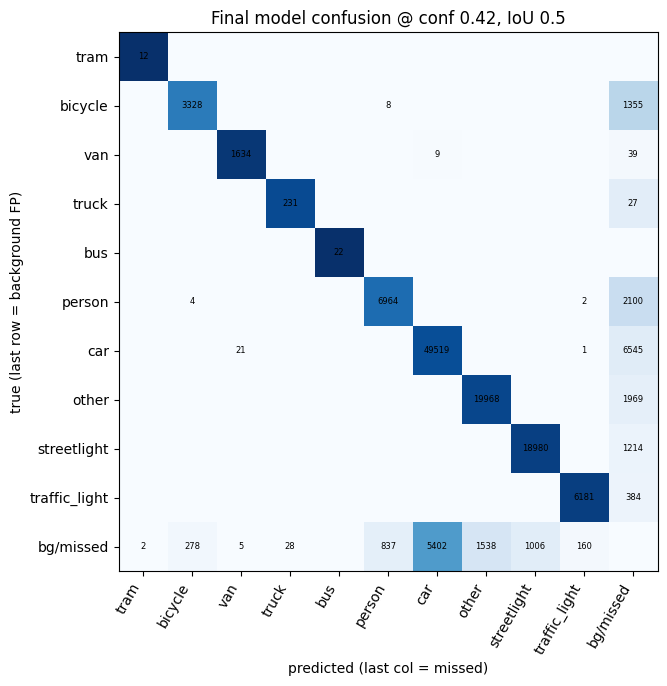

In [8]:
FINAL_ID, FINAL_MODE = D.get("final_model"), D.get("final_mode", "full")
if FINAL_ID:
    TT = ALL[(ALL.experiment_id == FINAL_ID) & (ALL.eval_split == "test") & (ALL.inference_mode == FINAL_MODE)]
    TT = TT if len(TT) else ALL[(ALL.experiment_id == FINAL_ID) & (ALL.eval_split == "val")]
    F = TT.iloc[0]
    gt_name = "aerial_test" if F.eval_split == "test" else "aerial_val"
    dets = ml.load_json(F.preds_path)
    conf = F.conf_at_best_f1 or 0.25
    # class-wise AP heatmap across key experiments on the same split
    K = ALL[(ALL.eval_split == F.eval_split) & ALL.per_class_AP.notna() & ALL.stage.isin(["S0", "S3", "S6"])]
    H = pd.DataFrame({r.experiment_id: r.per_class_AP for r in K.itertuples()}).reindex(ml.CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(1.2 * len(H.columns) + 4, 5))
    HV = H.astype(float).values
    im = ax.imshow(HV, cmap="viridis"); plt.colorbar(im)
    ax.set_xticks(range(len(H.columns))); ax.set_xticklabels(H.columns, rotation=60, ha="right", fontsize=7); ax.set_yticks(range(len(H))); ax.set_yticklabels(H.index)
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            v = HV[i, j]
            if not np.isnan(v): ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="w", fontsize=7)
    ax.set_title(f"Class-wise AP@0.5:0.95 ({F.eval_split})"); ml.savefig("R_classwise_AP.png"); plt.show()
    SB = pd.DataFrame(ml.size_bucket_recall(ml.json_path(gt_name), dets, conf)).T
    display(SB); ml.save_table(SB.reset_index().rename(columns={"index": "size"}), "R_final_size_bucket_recall")
    M = ml.confusion_matrix(ml.json_path(gt_name), dets, conf)
    lab = ml.CLASS_NAMES + ["bg/missed"]
    fig, ax = plt.subplots(figsize=(8, 7))
    Mn = M / np.maximum(M.sum(1, keepdims=True), 1)
    ax.imshow(Mn, cmap="Blues"); ax.set_xticks(range(len(lab))); ax.set_xticklabels(lab, rotation=60, ha="right"); ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab)
    ax.set_xlabel("predicted (last col = missed)"); ax.set_ylabel("true (last row = background FP)")
    for i in range(len(lab)):
        for j in range(len(lab)):
            if M[i, j]: ax.text(j, i, M[i, j], ha="center", va="center", fontsize=6)
    ax.set_title(f"Final model confusion @ conf {conf:.2f}, IoU 0.5"); ml.savefig("R_final_confusion.png"); plt.show()

OSError: cannot read /content/mavrec_local/images/aerial_1280/test/scene_2_Crossroad_campus_30Sec_droneView_01_000147.jpg

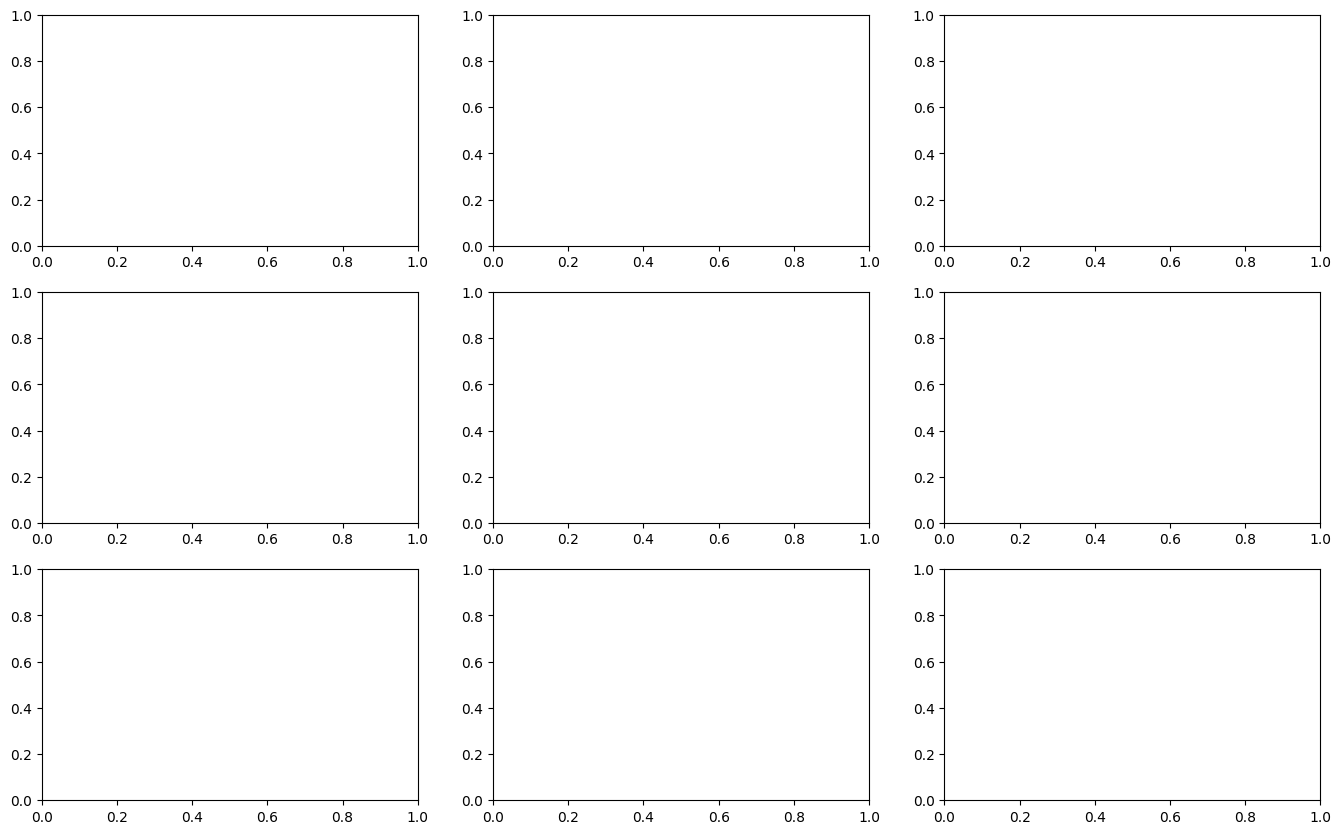

In [9]:
if FINAL_ID:
    base = ALL[(ALL.stage == "S0") & (ALL.resolution == 640) & (ALL.eval_split == F.eval_split)]
    items = ([("Baseline YOLOv7 500/640", base.iloc[0].preds_path, base.iloc[0].conf_at_best_f1)] if len(base) else []) + [("Final", F.preds_path, conf)]
    ml.prediction_grid(items, gt_name, "aerial_1280", n=3, out_path=os.path.join(CFG["figures_dir"], "R_qualitative_grid.png"))

lines = ["# MAVREC project — results summary", f"_generated {ml.now()} by notebook 10, lib {ml.LIB_VERSION}_", "", "## Decisions"]
lines += [f"- **{k}**: {v}" for k, v in D.items()]
if FINAL_ID:
    lines += ["", "## Final model", f"- `{FINAL_ID}` ({FINAL_MODE}) on **{F.eval_split}**: mAP50-95 {F.mAP50_95:.1f}, AP50 {F.mAP50:.1f}, APS {F.APS}, APt {F.APt}, recall {F.recall:.1f}, {F.FPS} FPS"]
lines += ["", "## Files", f"- master table: `tables/master_results.csv`", f"- figures: `figures/` ({len(os.listdir(CFG['figures_dir']))} files)"]
os.makedirs(os.path.join(CFG["results_root"], "report"), exist_ok=True)
ml.Path(os.path.join(CFG["results_root"], "report", "summary.md")).write_text("\n".join(lines))
print("\n".join(lines))

## 7 · Qualitative grid (baseline vs final) and summary

## Claims checklist for the report
- *From the MAVREC paper:* dataset, classes, ground-view pretraining result for D-DETR (Table 3), YOLOv7 being the strongest supervised aerial baseline.
- *Already done in Review 2:* YOLOv7 500/100, 640 vs 960 (mAP50 0.157 → 0.357; not converged, different val).
- *New in this project:* canonical protocol + unified evaluator (maxDets 300, native-resolution APS), multi-family screening, resolution and data-scaling curves,
  tiling vs resolution on APS, ground→aerial pretraining on a non-DETR detector, final ablation on the held-out test set, VisDrone transfer.
- *Findings:* only what the tables above show (state seed count; differences < 1 AP point are ties).
- *Future work:* full 8,605-frame training, semi-supervised curriculum (paper §4.2), cross-view fusion, DINO with a larger GPU.